# Pregunta busqueda

## Clases Base

In [ ]:
!pip install torch --index-url https://download.pytorch.org/whl/cu121
!pip -q install -U transformers accelerate sentencepiece bitsandbytes huggingface_hub


Looking in indexes: https://download.pytorch.org/whl/cu121
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 116.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 765.1/765.1 kB 58.7 MB/s eta 0:00:00


In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

# Posible texto generado

class Node:
    def __init__(self, full_text: str, token: str, puntaje: float, profundidad: int = 0):
        self.full_text = full_text
        self.token = token
        self.children = []
        self.score = puntaje
        self.profundidad = profundidad

    def agregar_hijo(self, nodo):
        self.children.append(nodo)

    def show(self):
        grafo = nx.DiGraph()

        def recorrer(nodo: Node):
            nodo_id = id(nodo)

            grafo.add_node(nodo_id, label=nodo.token.replace("\n", "\\n"))

            for hijo in nodo.children:
                recorrer(hijo)
                grafo.add_edge(nodo_id, id(hijo), weight=f"{hijo.score:.3f}")

        recorrer(self)

        def calcular_posiciones(nodo):
            posiciones = {}
            def asignar(nodo, profundidad, x_actual):
                nodo_id = id(nodo)
                if len(nodo.children) == 0:
                    posiciones[nodo_id] = (x_actual[0], -profundidad)
                    x_actual[0] += 1
                    return posiciones[nodo_id][0]
                xs_hijos = []
                for hijo in nodo.children:
                    xs_hijos.append(asignar(hijo, profundidad + 1,x_actual))

                x = sum(xs_hijos) / len(xs_hijos)
                posiciones[nodo_id] = (x, -profundidad)
                return x

            asignar(nodo, 0, [0])
            return posiciones

        pos = calcular_posiciones(self)
        plt.figure(figsize=(16, 10))

        labels = nx.get_node_attributes(grafo, "label")
        edge_labels = nx.get_edge_attributes(grafo, "weight")
        nx.draw(
            grafo,
            pos,
            labels=labels,
            node_size=2500,
            font_size=8,
            arrows=True
        )

        nx.draw_networkx_edge_labels(
            grafo,
            pos,
            edge_labels=edge_labels,
            font_size=7
        )

        plt.title("Árbol de generación")
        plt.axis("off")
        plt.tight_layout()
        plt.show()

In [ ]:
from huggingface_hub import login
import os
from dotenv import load_dotenv
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
import torch

class ModelFactory:
    def __init__(self):
        load_dotenv()

        login_token = os.getenv("HUGGING_FACE_TOKEN")
        if login_token is None:
            raise ValueError("Recuerda que debes agregar un archivo .env al entorno.")

        login(token=login_token)

        self.model_name = "mistralai/Mistral-7B-Instruct-v0.3"

    def get_model(self):
        quantization_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_compute_dtype=torch.float16,
        )
        model = AutoModelForCausalLM.from_pretrained(
            self.model_name,
            quantization_config=quantization_config,
            device_map="auto",
        )
        return model

    def get_tokenizer(self):
        tokenizer = AutoTokenizer.from_pretrained(self.model_name)
        return tokenizer

In [ ]:
import numpy as np
import torch


class SuccesorGenerator:
    _instancia = None

    def __new__(cls):
        if cls._instancia is None:
            cls._instancia = super().__new__(cls)
        return cls._instancia

    def __init__(self):
        if hasattr(self, '_inicializado'):
            return
        model_factory = ModelFactory()
        self.model = model_factory.get_model()
        self.tokenizer = model_factory.get_tokenizer()

    def _decode_token(self, indice: int) -> str:
        if int(indice) == self.tokenizer.eos_token_id:
            return "<eos>"

        token = self.tokenizer.convert_ids_to_tokens([int(indice)])[0]
        text = token.replace("▁", " ")
        return text

    def _get_probabilities(self, input: str) -> np.ndarray:
        """
        Devuelve las probabilidades del vocabulario para el próximo token
        como un numpy.ndarray.
        """
        inputs = self.tokenizer(
            input,
            return_tensors="pt"
        )
        inputs = {k: v.to(self.model.device) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = self.model(**inputs)
            logits = outputs.logits[:, -1, :]
            probs = torch.softmax(logits, dim=-1)

        return probs.squeeze(0).to(torch.float32).cpu().numpy()

    def get_succesors_best_k(self, input:str, k: int):
        """
        Devuelve una lista de tamaño k de la forma

        [
            [probabilidad, string_del_token],
            [probabilidad, string_del_token],
            [probabilidad, string_del_token],
        ]
        con los k resultados de mayor probabilidad.
        """
        token_probabilities = self._get_probabilities(input)
        # Índices de los k mayores, ordenados de mayor a menor
        idx = np.argpartition(token_probabilities, -k)[-k:]
        idx = idx[np.argsort(token_probabilities[idx])[::-1]]

        return [
            [
                float(token_probabilities[indice]),
                self._decode_token(indice)
            ]
            for indice in idx
        ]

    def get_sucesors_p_min(self, input: str, min_p: float, n: int):
        """
        Devuelve un sampleo sin reposición de n tokens entre aquellos cuya
        probabilidad supera min_p, siguiendo probabilidades renormalizadas
        y ordenados de mayor a menor probabilidad original.

        Si tras el filtro hay menos de n tokens disponibles, retorna todos.

        [
            [probabilidad, string_del_token],
            [probabilidad, string_del_token],
            [probabilidad, string_del_token],
        ]
        """
        probs = self._get_probabilities(input)

        # Paso 1: filtrar por min_p
        indices = np.where(probs >= min_p)[0]

        # Si hay menos candidatos que n, retornar todos ordenados
        if len(indices) <= n:
            indices = indices[np.argsort(probs[indices])[::-1]]
            return [
                [
                    float(probs[i]),
                    "<eos>" if int(i) == self.tokenizer.eos_token_id
                    else self.tokenizer.decode([int(i)])
                ]
                for i in indices
            ]

        # Paso 2: renormalizar probabilidades para que sumen 1
        filtered_probs = probs[indices]
        renormalized_probs = filtered_probs / filtered_probs.sum()

        # Paso 3: sampleo sin reposición de n tokens
        sampled_positions = np.random.choice(
            len(indices),
            size=n,
            replace=False,
            p=renormalized_probs
        )
        sampled_indices = indices[sampled_positions]

        # Ordenar de mayor a menor probabilidad original
        sampled_indices = sampled_indices[np.argsort(probs[sampled_indices])[::-1]]

        return [
            [
                float(probs[i]),
                self._decode_token(i)
            ]
            for i in sampled_indices
        ]

# Actividades

In [ ]:
import math

def crear_y_agregar_hijo(nodo_padre: Node, token: str, probabilidad: float) -> Node:
    # 1. Crear un nuevo nodo: texto = texto del nodo padre agregando el nuevo token.
    texto = nodo_padre.full_text + token

    # 2. Calcular log probabilidad normalizada con la del padre
    n_padre = nodo_padre.profundidad
    suma_log_padre = nodo_padre.score * n_padre
    log_proba = (suma_log_padre + math.log(probabilidad)) / (n_padre + 1)

    hijo = Node(full_text=texto, token=token,
                puntaje=log_proba, profundidad=n_padre + 1)

    # 3. Agregar el nuevo nodo como hijo del nodo padre.
    nodo_padre.agregar_hijo(hijo)
    return hijo

def beam_search(nodo_raiz: Node, generador: SuccesorGenerator, profundidad: int, beam_size: int) -> Node:
    activos = []
    activos.append(nodo_raiz)
    depth = 0
    while depth < profundidad and activos != []:
        # revisamos si ya hay una solución (<eos>) en el beam actual
        soluciones = [n for n in activos if n.token == "<eos>"]
        if soluciones:
            return max(soluciones, key=lambda n: n.score)

        new_beam = []
        for nodo in activos:
            sucesores = generador.get_succesors_best_k(nodo.full_text, beam_size)
            for suc in sucesores:
                hijo = crear_y_agregar_hijo(nodo, suc[1], suc[0])
                new_beam.append(hijo)
        new_beam.sort(key=lambda n: n.score, reverse=True)
        activos = new_beam[:beam_size]
        depth += 1
    return activos[0]

def p_min_beam_search(nodo_padre: Node, generador: SuccesorGenerator, profundidad: int, p_min: float, beam_size:int):
    activos = [nodo_padre]
    depth = 0
    while depth < profundidad and activos:
        # revisamos si ya hay una solución (<eos>) en el beam actual
        soluciones = [n for n in activos if n.token == "<eos>"]
        if soluciones:
            return max(soluciones, key=lambda n: n.score)

        new_beam = []
        for nodo in activos:
            sucesores = generador.get_sucesors_p_min(nodo.full_text, p_min, beam_size)
            for suc in sucesores:
                hijo = crear_y_agregar_hijo(nodo, suc[1], suc[0])
                new_beam.append(hijo)
        new_beam.sort(key=lambda n: n.score, reverse=True)
        activos = new_beam[:beam_size]
        depth += 1
    return activos[0]

def greedy_search(nodo_padre: Node, generador: SuccesorGenerator, profundidad: int) -> Node:
    nodo_actual = nodo_padre
    for _ in range(profundidad):
        succ = generador.get_succesors_best_k(nodo_actual.full_text, 1)
        crear_y_agregar_hijo(nodo_actual, succ[0][1], succ[0][0])
        nodo_actual = nodo_actual.children[-1]
    return nodo_actual

def p_min_generation(nodo_padre: Node, generador: SuccesorGenerator, profundidad: int, p_min: float):
    activos = []
    activos.append(nodo_padre)
    depth = 0
    while depth < profundidad and activos != []:
        new_beam = []
        for nodo in activos:
            sucesor = generador.get_sucesors_p_min(nodo.full_text, p_min, 1)
            hijo = crear_y_agregar_hijo(nodo, sucesor[0][1], sucesor[0][0])
            new_beam.append(hijo)
        activos = new_beam
        depth += 1
    return activos[-1]

def random_sampling_generation(nodo_padre: Node, generador: SuccesorGenerator, profundidad: int) -> Node:
    nodo_actual = nodo_padre
    for _ in range(profundidad):
        sucesores = generador.get_sucesors_p_min(nodo_actual.full_text, 0.0, 1)
        prob, token = sucesores[0]
        nodo_actual = crear_y_agregar_hijo(nodo_actual, token, prob)
    return nodo_actual

# Cambiamos el beam size a un cálculo dinámico  de decaimiento lineal:

def beam_size_custom(depth: int, profundidad: int, beam_max: int, beam_min: int):
    if profundidad <= 1:
        return beam_max
    factor = depth / (profundidad - 1)
    beam_size = beam_max - (beam_max - beam_min) * factor
    return max(beam_min, round(beam_size))

def beam_search_custom(nodo_padre: Node, generador: SuccesorGenerator, profundidad:int, beam_size_max: int, beam_size_min: int):
    activos = []
    activos.append(nodo_padre)
    best_state = nodo_padre
    depth = 0

    while depth < profundidad and activos != []:
        # revisamos si ya hay una solución (<eos>) en el beam actual
        soluciones = [n for n in activos if n.token == "<eos>"]
        if soluciones:
            return max(soluciones, key=lambda n: n.score)

        # calculamos el nuevo beam size
        beam_size = beam_size_custom(depth, profundidad, beam_size_max, beam_size_min)

        new_beam = []
        for nodo in activos:
            sucesores = generador.get_succesors_best_k(nodo.full_text, beam_size)
            for suc in sucesores:
                hijo = crear_y_agregar_hijo(nodo, suc[1], suc[0])
                new_beam.append(hijo)
        if new_beam == []:
            return best_state
        new_beam.sort(key=lambda n: n.score, reverse=True)
        if new_beam[0].score > best_state.score:
            best_state = new_beam[0]
        activos = new_beam[:beam_size]
        depth += 1

    return best_state


In [ ]:
generador = SuccesorGenerator()


config.json:   0%|          | 0.00/601 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/141k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/587k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

# Test de uso

Aquí se muestra un pequeño ejemplo de como debería llamarse a las funciones de busqueda. Puedes usar el método show para poder visualizar si la estructura del arbol coincide con lo esperado según el algoritmo de busqueda.

In [ ]:
prompt = "How are you? \n"
profundidad = 10

How are you? 
<0x0A><0x0A><0x0A>I'm just a computer program
-0.5813522114780743
10


/tmp/ipykernel_3543/1845879459.py:73: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


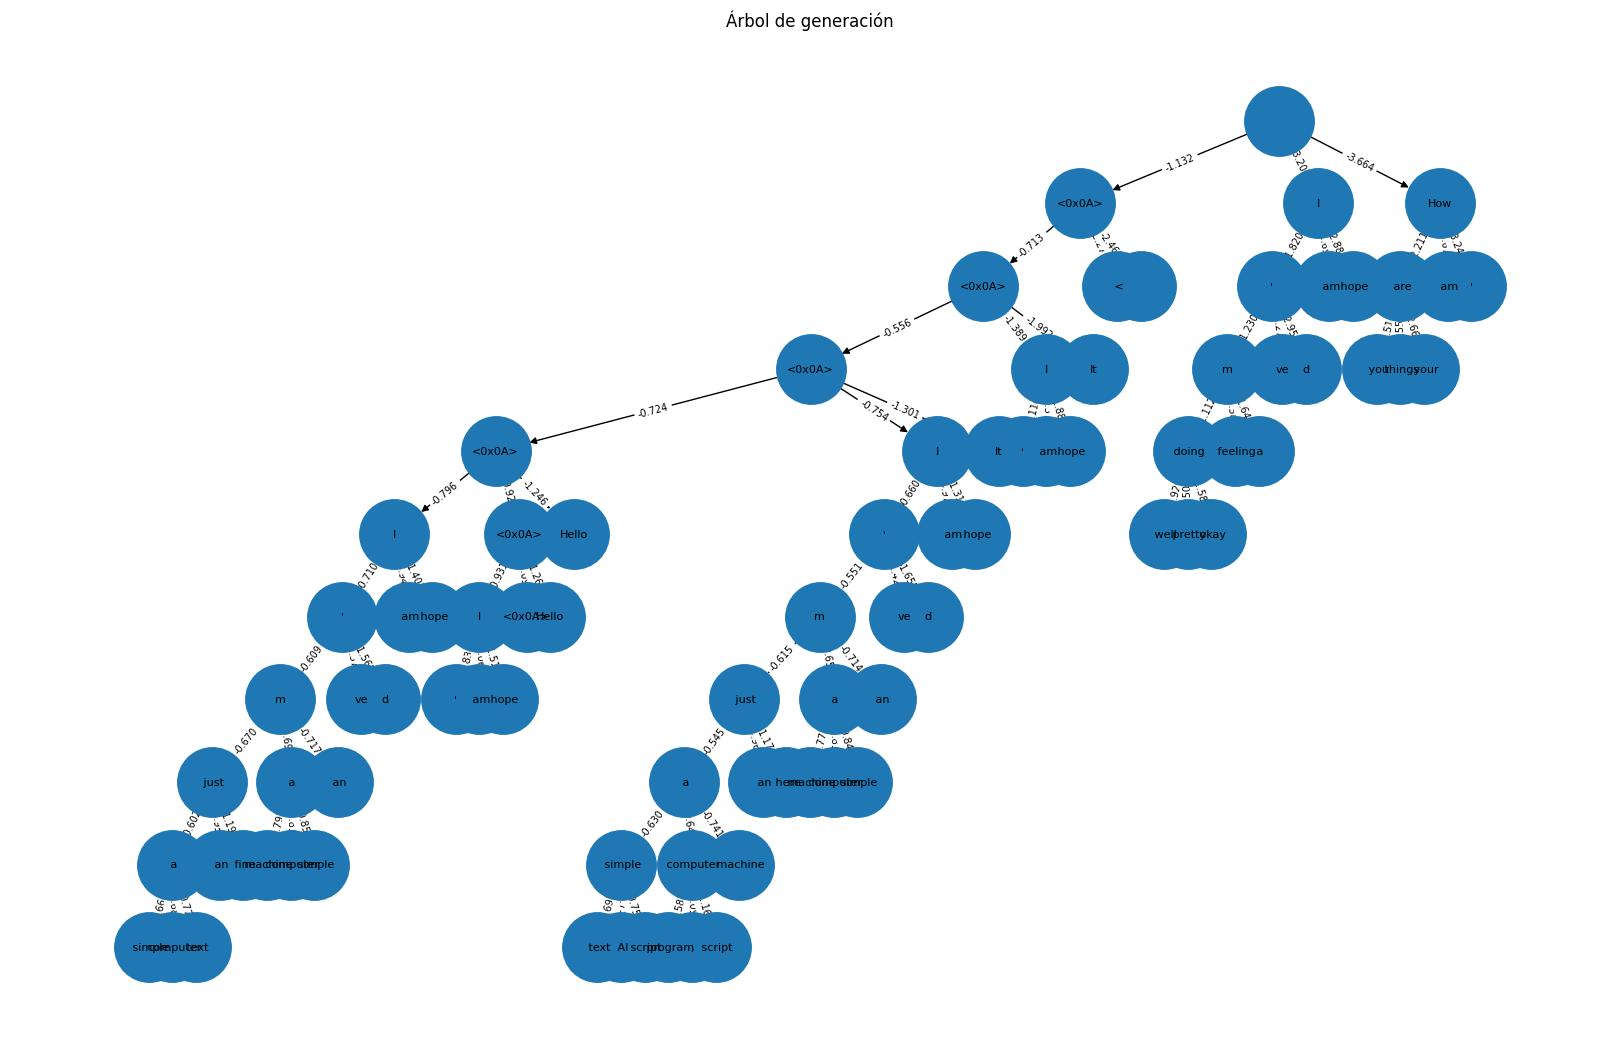

In [ ]:
# Crear la raíz con el texto inicial
nodo_raiz = Node(full_text=prompt, token="", puntaje=0.0)

# Correr la búsqueda
mejor_nodo = beam_search(nodo_raiz, generador, profundidad, 3)

# Ver el resultado
print(mejor_nodo.full_text)
print(mejor_nodo.score)
print(mejor_nodo.profundidad)
nodo_raiz.show()


## Comparacion algoritmos

La idea es que ahora compares como se comportan distintos algoritmos ante el siguiente prompt.

In [ ]:
prompt = "Explain why AI is important in 60 words.\n"
profundidad = 70

Partimos con el **Beam Search** Normal con 4 tamaños en el beam:

===== Beam Search con k = 3 =====
Texto: Explain why AI is important in 60 words.
<0x0A><0x0A>AI is crucial because it automates complex tasks, learns from data, adapts to new information, and makes decisions with minimal human intervention. This empowers businesses to scale operations, improve efficiency, and deliver personalized experiences, ultimately driving growth and innovation.<eos>
Puntaje: -0.3868495421882551
Profundidad: 57
Expansiones: 169
 
===== Beam Search con k = 5 =====
Texto: Explain why AI is important in 60 words.
<0x0A> AI's importance lies in its ability to automate complex tasks, learn from data, and make decisions with minimal human intervention. This empowers businesses to scale operations, improve efficiency, and deliver personalized experiences, ultimately driving growth and innovation.<eos>
Puntaje: -0.34576172766941343
Profundidad: 52
Expansiones: 256
 
===== Beam Search con k = 10 =====
Texto: Explain why AI is important in 60 words.
<0x0A> AI's importance 

/tmp/ipykernel_3543/1845879459.py:73: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 23427 (\N{CJK UNIFIED IDEOGRAPH-5B83}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


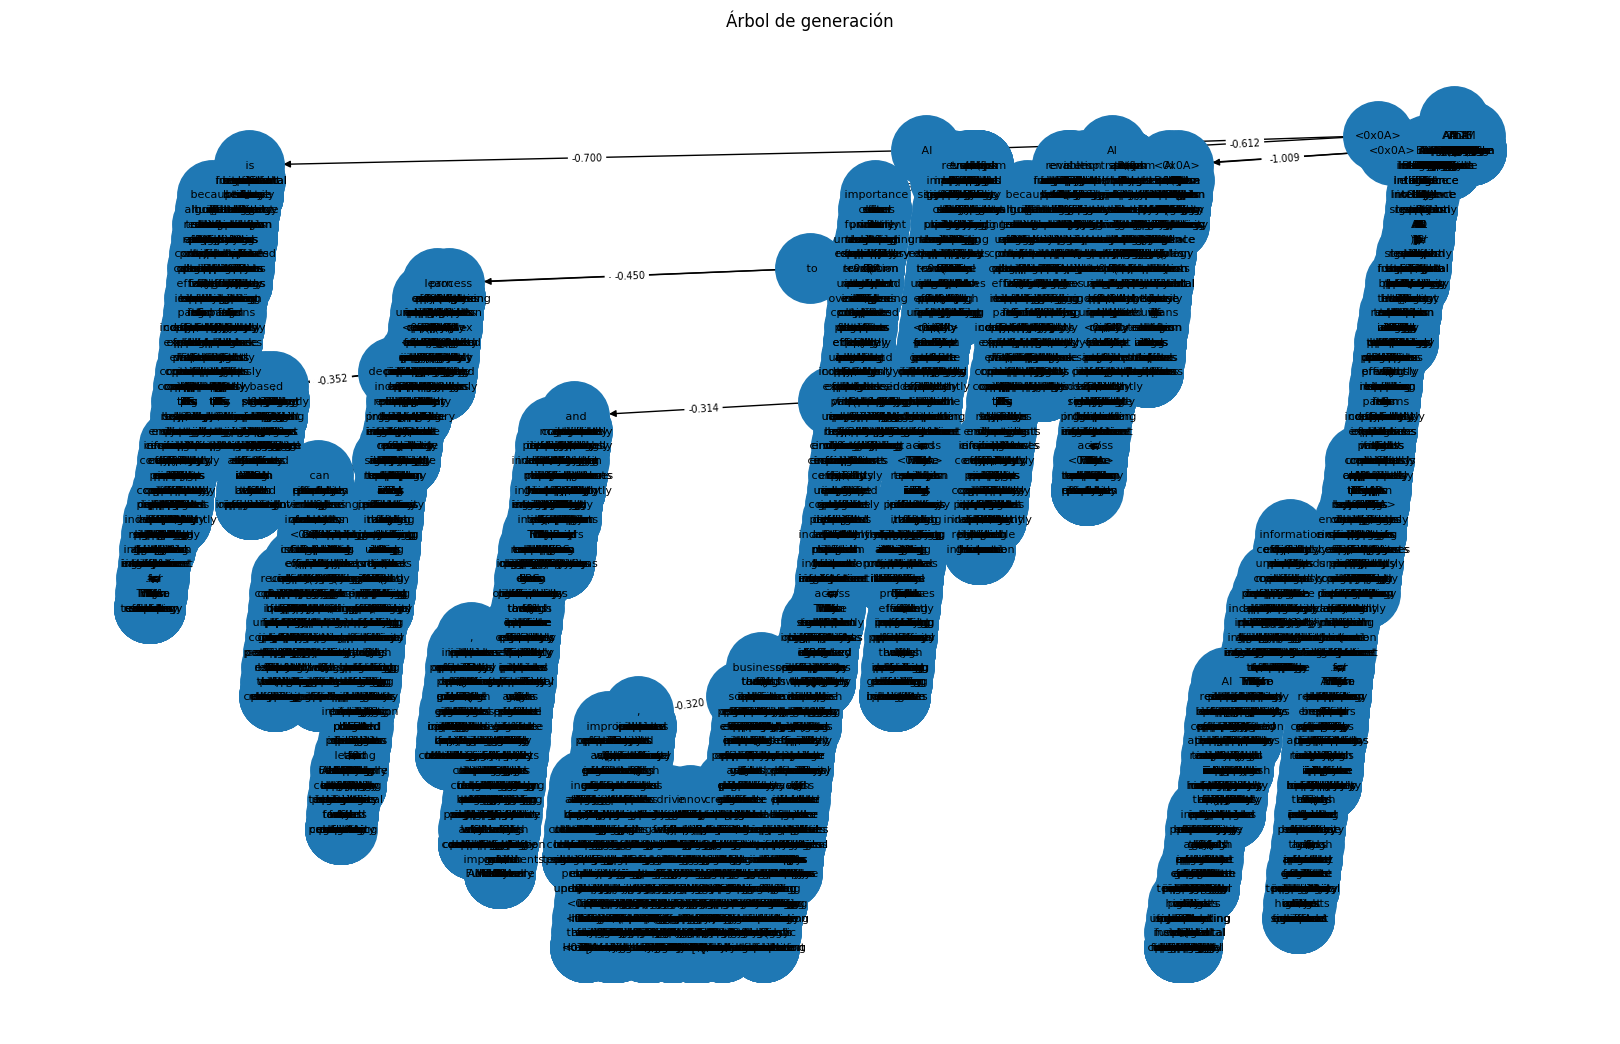

In [ ]:
for bs in [3, 5, 10, 15]:
    nodo_raiz = Node(full_text=prompt, token="", puntaje=0.0)
    mejor_nodo = beam_search(nodo_raiz, generador, profundidad, bs)

    print(f"===== Beam Search con k = {bs} =====")
    print(f'Texto: {mejor_nodo.full_text}')
    print(f'Puntaje: {mejor_nodo.score}')
    print(f'Profundidad: {mejor_nodo.profundidad}')
    print(f'Expansiones: {1 + (mejor_nodo.profundidad - 1) * bs}')
    print(' ')

nodo_raiz.show()

Sabemos que cada vez que llamamos al generador se expande un nodo. La formula viene porque si tenemos una profundidad de 20: son 19 niveles (contando el 0 que tiene solamente al nodo raiz). Este nodo se expande una sola vez y genera beam_size hijos, luego por profundidad-1 veces, se expande beam_size veces. Obtenemos:
$$
Expansiones = 1 + beam\_size*(profundidad -1)
$$


**P_min Beam Search**

===== P_min Beam Search con k = 3 =====
Texto: Explain why AI is important in 60 words.

AI revolutionizes decision-making, automating complextasks, learning from data, and adaptingto new situations. It drives innovation, improves efficiency, and enhances human capabilities, enabling usto solvecomplexproblems, make predictions,and create personalized experiences.<eos>
Puntaje: -0.5210278568024488
Profundidad: 56
Expansiones: 166
 
===== P_min Beam Search con k = 10 =====
Texto: Explain why AI is important in 60 words.

AI revolutionizes industriesbyautomatingrepetitivetasks,enhancingproductivity, and enabling data-drivendecision-making.It learns,adapts,andimprovesovertime,facilitatinginnovation,efficiency,andcompetitiveadvantage.AI'spotentialimpactonhumanityisboundless
Puntaje: -0.5114456383626736
Profundidad: 70
Expansiones: 691
 
===== P_min Beam Search con k = 15 =====
Texto: Explain why AI is important in 60 words.

AIrevolutionizesdecision-making,automatesrepetitivetasks,enhancesp

/tmp/ipykernel_3543/1845879459.py:73: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


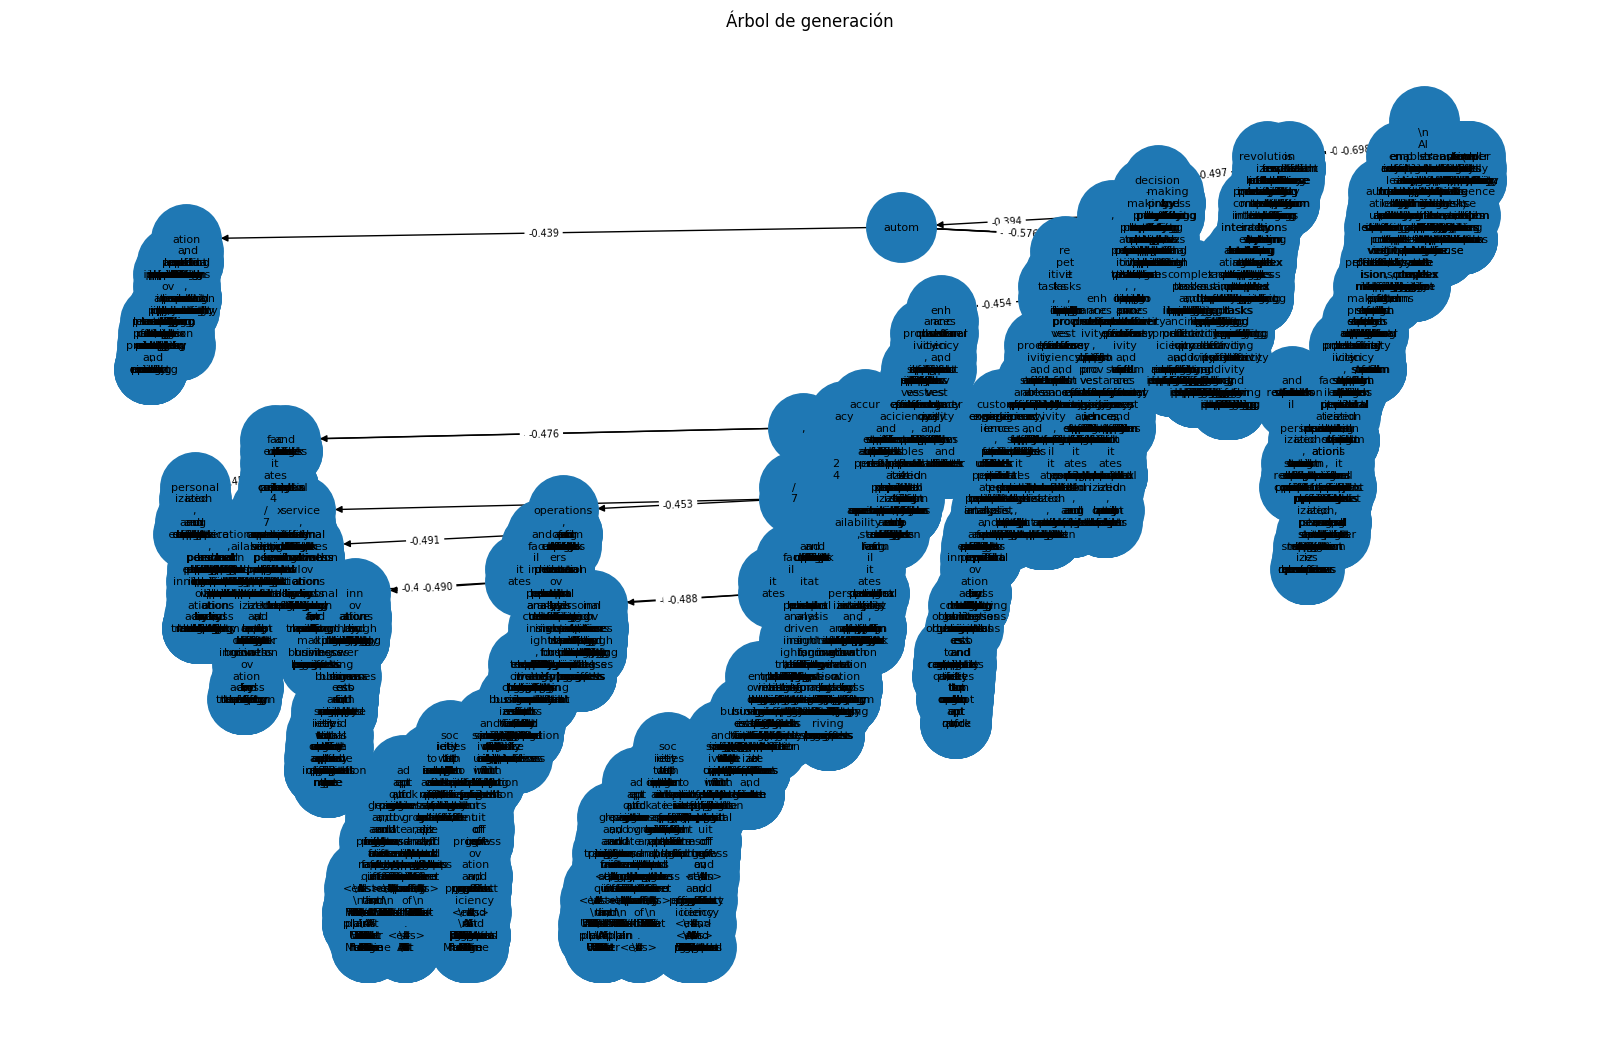

In [ ]:
for bs in [3, 10, 15]:
    nodo_raiz = Node(full_text=prompt, token="", puntaje=0.0)
    mejor_nodo = p_min_beam_search(nodo_raiz, generador, profundidad, 0.01, bs)

    print(f"===== P_min Beam Search con k = {bs} =====")
    print(f'Texto: {mejor_nodo.full_text}')
    print(f'Puntaje: {mejor_nodo.score}')
    print(f'Profundidad: {mejor_nodo.profundidad}')
    print(f'Expansiones: {1 + (mejor_nodo.profundidad - 1) * bs}')
    print(' ')

nodo_raiz.show()

**Greedy**

===== Greedy =====
Score: -0.4034
Expansiones: 70
Texto: Explain why AI is important in 60 words.
<0x0A> AI is crucial because it automates complex tasks, learns from data, adapts to new information, and makes decisions with minimal human intervention. This allows businesses to scale, improve efficiency, and provide personalized experiences, ultimately driving growth and innovation.<eos><0x0A><eos><eos><eos><eos><eos><0x0A> AI's ability to process vast amounts of data


/tmp/ipykernel_3543/1845879459.py:73: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


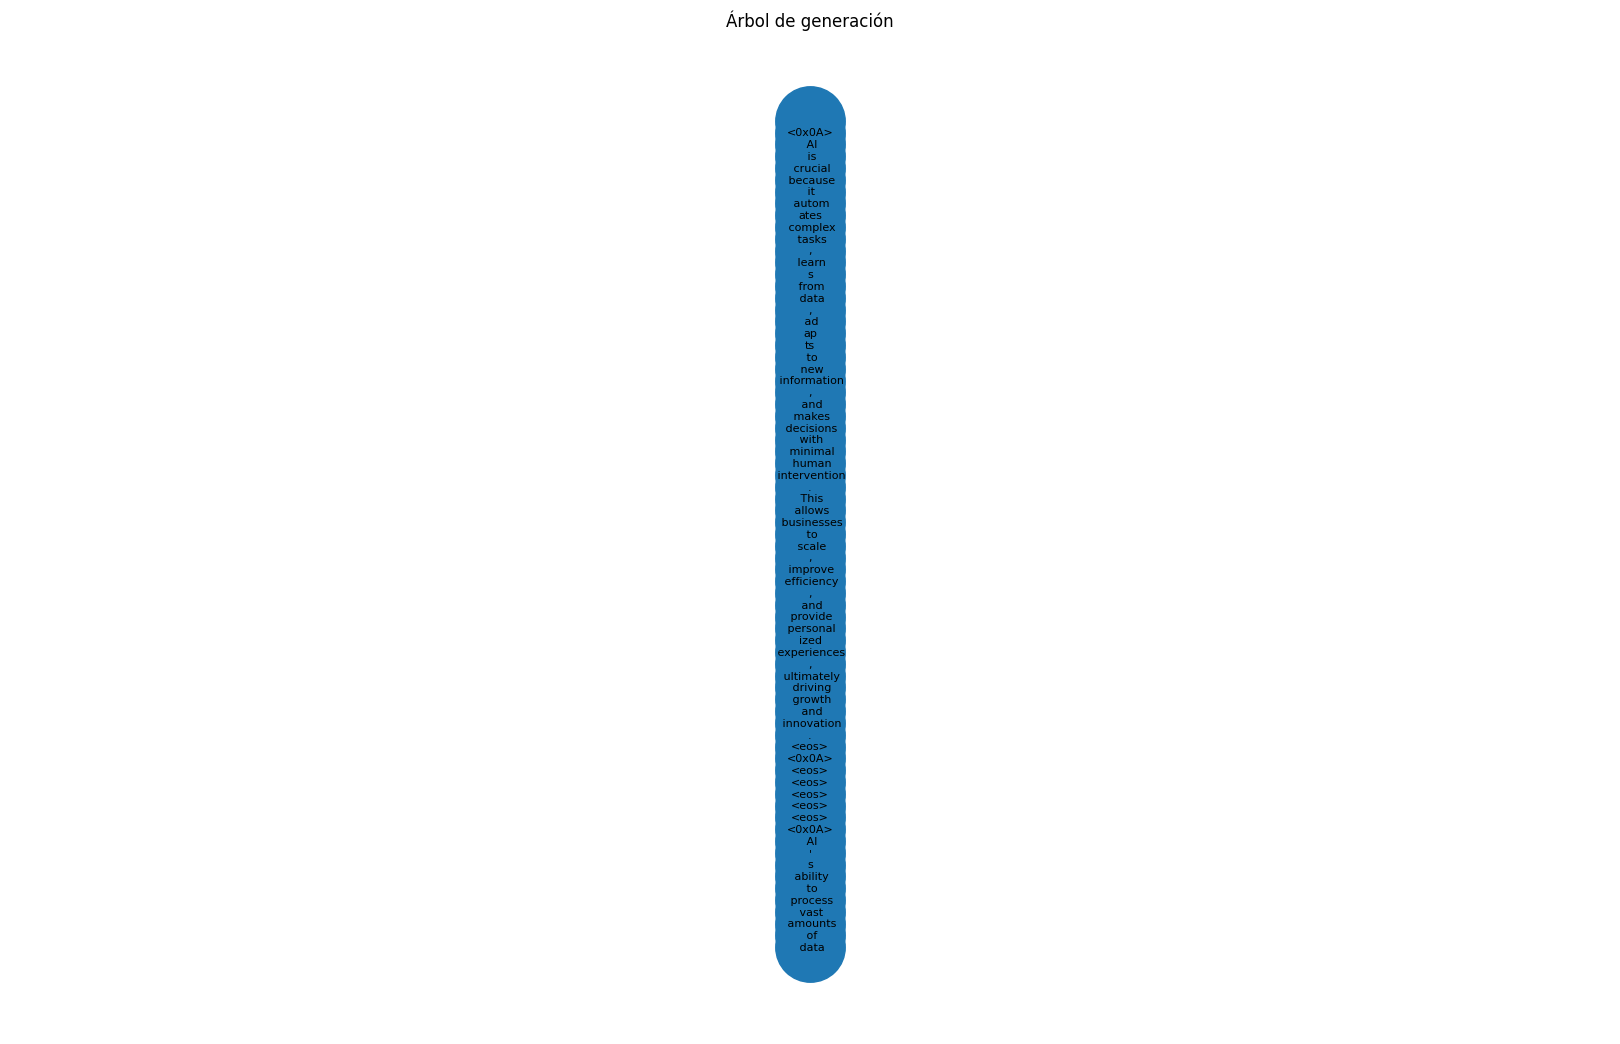

In [ ]:
nodo_raiz = Node(full_text=prompt, token="", puntaje=0.0)
mejor = greedy_search(nodo_raiz, generador, profundidad)
print(f'===== Greedy =====')
print(f"Score: {mejor.score:.4f}")
print(f"Expansiones: {profundidad}")
print(f"Texto: {mejor.full_text}")
nodo_raiz.show()

**P-min generation**

===== P_min generation =====
Score: -1.1122
Expansiones: 70
Texto: Explain why AI is important in 60 words.

AI accelerates innovation, automates repetitivetasks, enhances efficiency, drives insights from big data, personalizes customer experiences, and supports decision-making in dynamic andcomplex environments. Its importance liesin its ability to augmenthuman intelligence, creating solutions to intricateproblems and improvingour quality of life.<eos><0x0A><0x0A>#AI #


/tmp/ipykernel_3543/1845879459.py:73: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


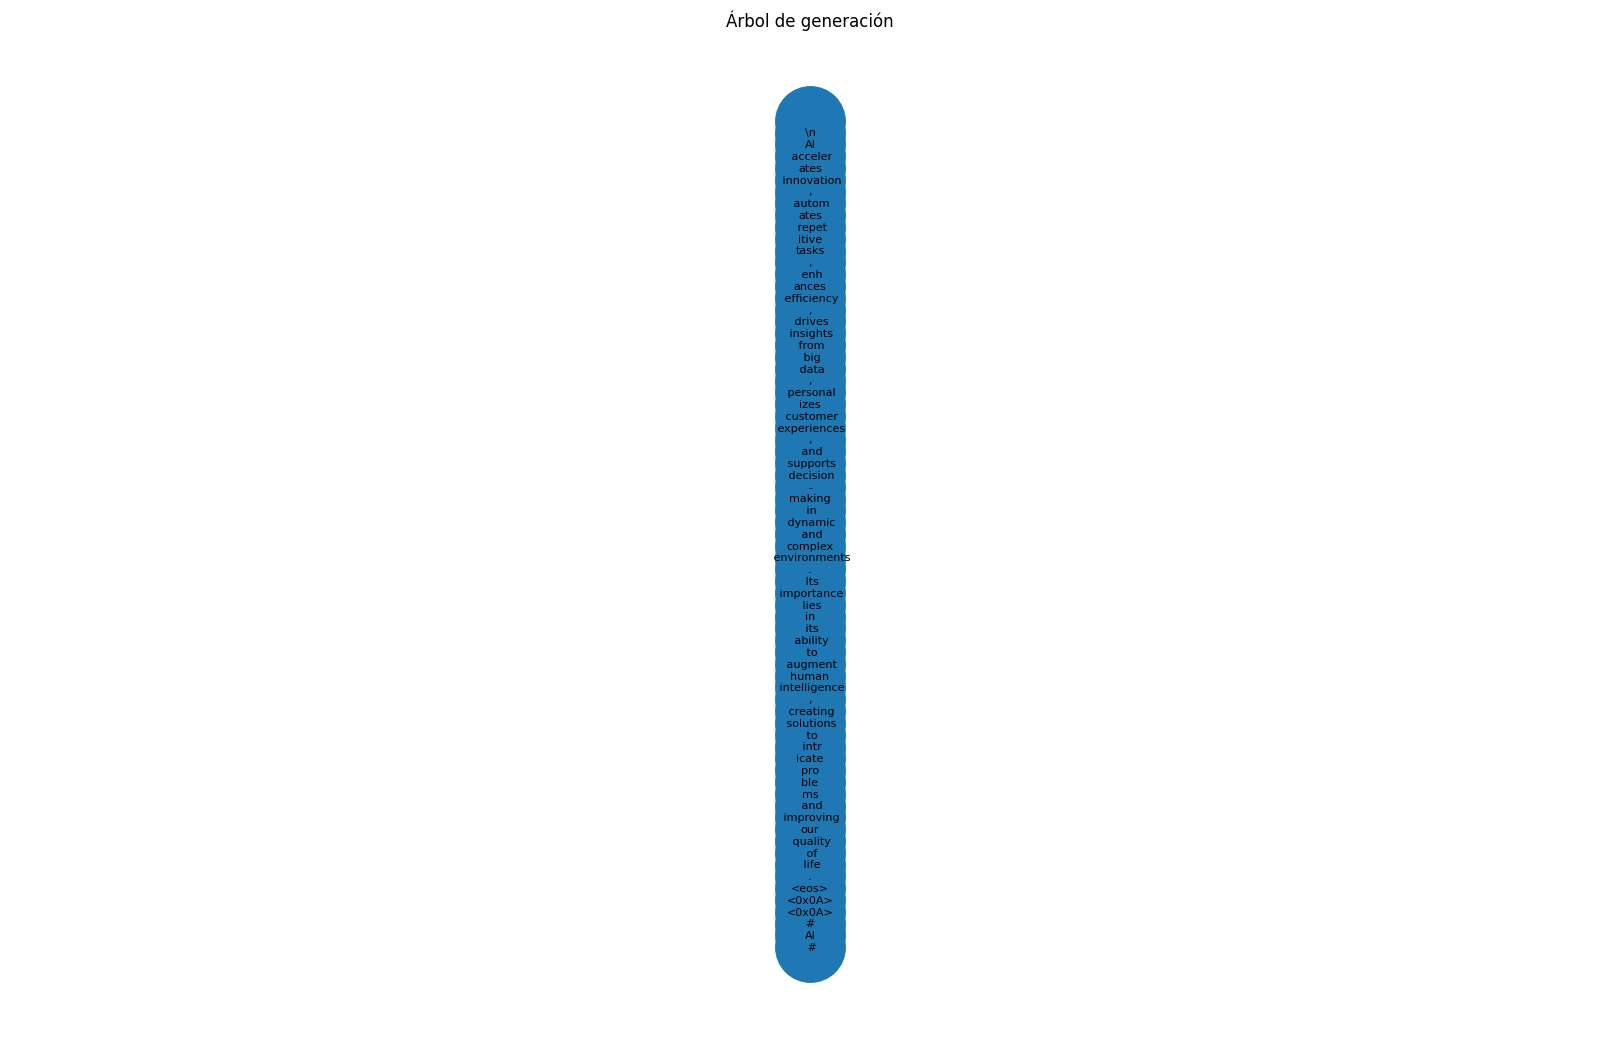

In [ ]:
nodo_raiz = Node(full_text=prompt, token="", puntaje=0.0)
mejor = p_min_generation(nodo_raiz, generador, profundidad, p_min=0.01)
print(f'===== P_min generation =====')
print(f"Score: {mejor.score:.4f}")
print(f"Expansiones: {profundidad}")
print(f"Texto: {mejor.full_text}")
nodo_raiz.show()

**Random Sampling**

===== Random Sampling =====
Score: -0.6365
Expansiones: 70
Texto: Explain why AI is important in 60 words.
<0x0A> Artificial Intelligence (AI) is a revolutionary technology that mimics human intelligence, learns from data, and improves over time. Its importance lies in its potential to automate tasks, improve efficiency, enhance decision-making, and drive innovation across various sectors, from healthcare to autonomous vehicles. AI has the power to reshape industries


/tmp/ipykernel_3543/1845879459.py:73: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


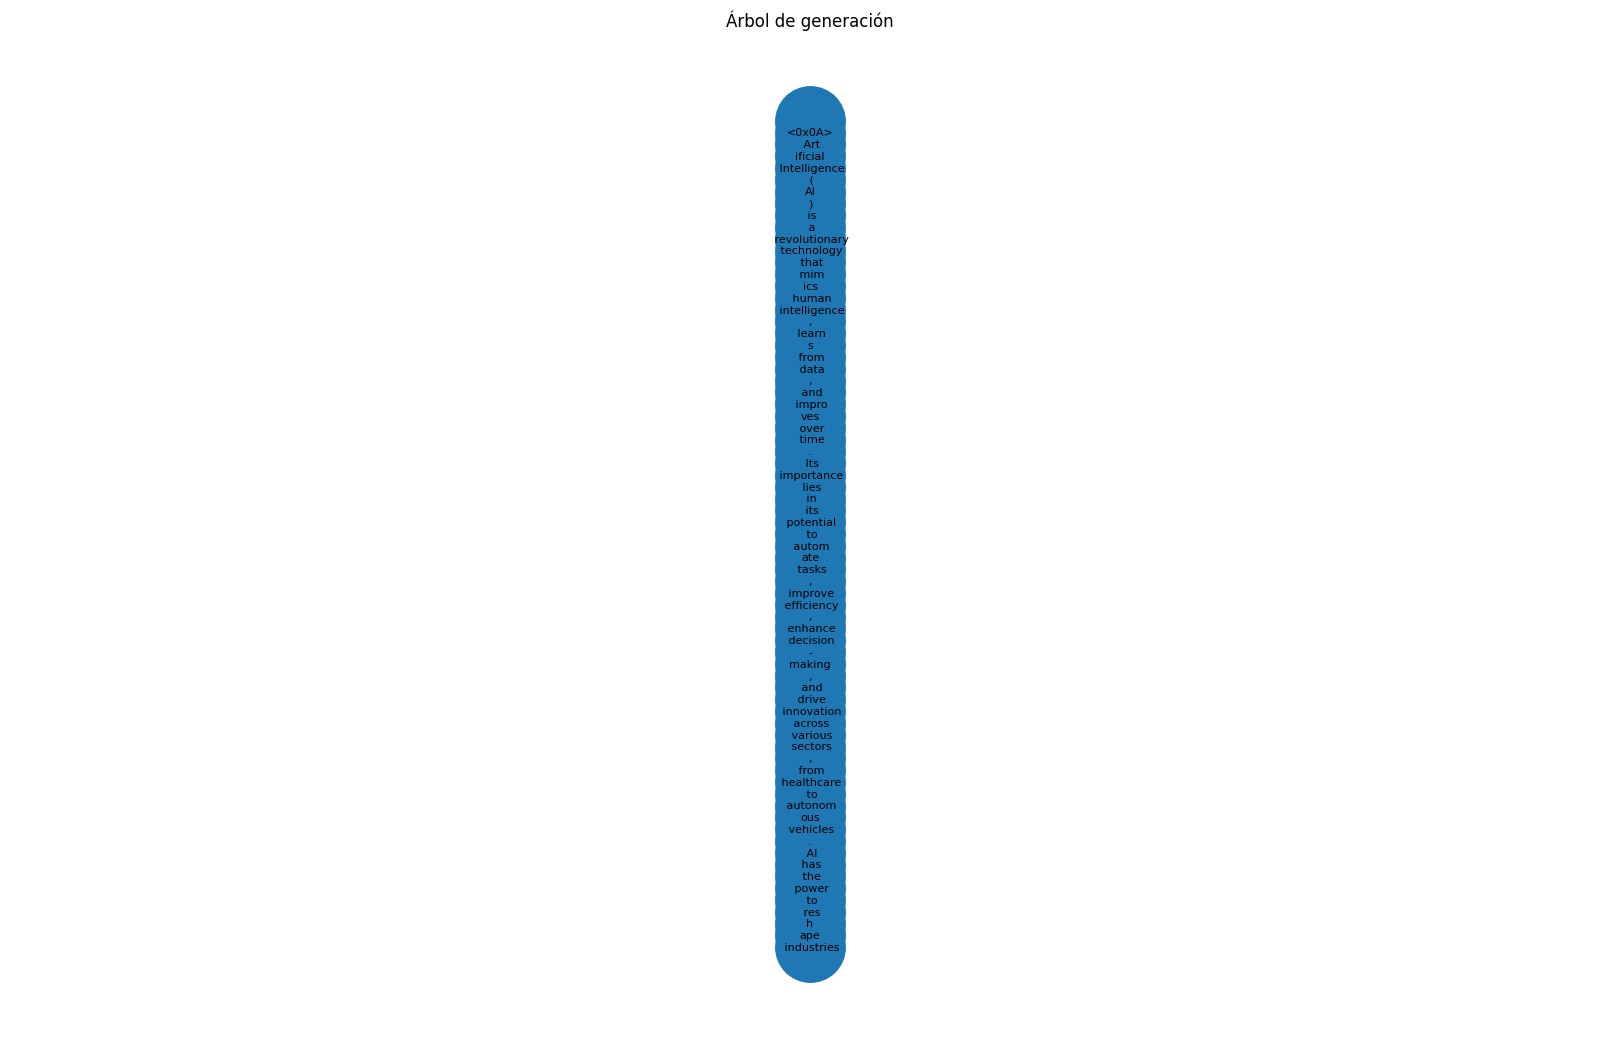

In [ ]:
nodo_raiz = Node(full_text=prompt, token="", puntaje=0.0)
mejor = random_sampling_generation(nodo_raiz, generador, profundidad)
print(f'===== Random Sampling =====')
print(f"Score: {mejor.score:.4f}")
print(f"Expansiones: {profundidad}")
print(f"Texto: {mejor.full_text}")
nodo_raiz.show()

**Beam Search Custom**
Lo que hice en el código anterior fue un beam search que cambiaba dinamicamente el beam size en donde con cada profundidad nueva, se vayan "angostando" los nodos expandidos, quedando una especie de embudo:


===== Beam Search Custom con Max Size = 5 =====
Texto: Explain why AI is important in 60 words.
<0x0A> AI's importance lies in its ability to automate complex tasks, learn from data, and make decisions with minimal human intervention. This empowers businesses to scale operations, improve efficiency, and deliver personalized experiences, ultimately driving growth and innovation.<eos>
Puntaje: -0.34576172766941343
Profundidad: 52
Expansiones: 766
 
===== Beam Search Custom con Max Size = 10 =====
Texto: Explain why AI is important in 60 words.
<0x0A><0x0A>Artificial Intelligence (AI) is crucial because it automates complex tasks, learns from data, adapts to new information, and makes decisions with minimal human intervention. AI's potential to revolutionize industries, improve efficiency, and drive innovation makes it a transformative technology for the future.<eos>
Puntaje: -0.33953249060956364
Profundidad: 63
Expansiones: 931
 
===== Beam Search Custom con Max Size = 15 =====
Texto: Ex

/tmp/ipykernel_3543/1845879459.py:73: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


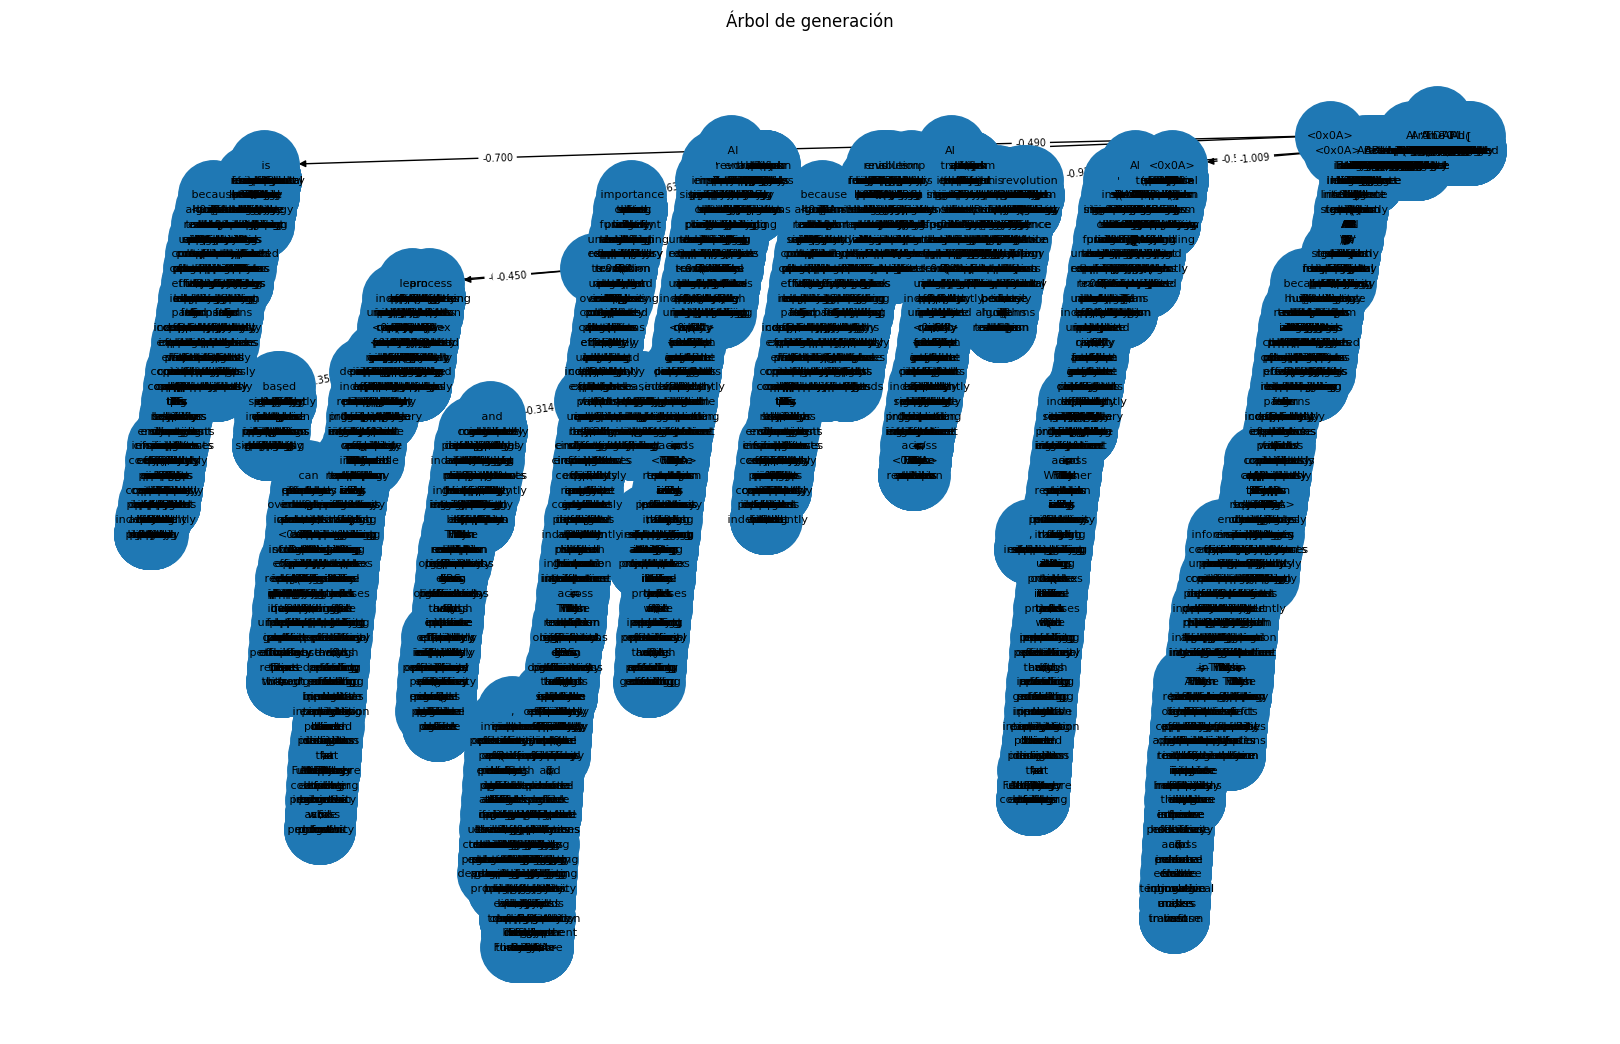

In [ ]:
for max_size in [5, 10, 15, 20]:
    nodo_raiz = Node(full_text=prompt, token="", puntaje=0.0)
    mejor_nodo = beam_search_custom(nodo_raiz, generador, profundidad, max_size, 1)

    print(f"===== Beam Search Custom con Max Size = {max_size} =====")
    print(f'Texto: {mejor_nodo.full_text}')
    print(f'Puntaje: {mejor_nodo.score}')
    print(f'Profundidad: {mejor_nodo.profundidad}')
    print(f'Expansiones: {1 + (mejor_nodo.profundidad - 1) * bs}')
    print(' ')

nodo_raiz.show()

## Análisis cuantitativo:
1. Si comparamos la log-probabilidad normalizada para las tres oraciones anteriores podemos ver que (teniendo en cuenta que mientras más cercano al 0 es una palabra más probable) desde el beam size = 3 hasta beam size = 10 se ve una mejora, pasando de una probabilidad de -0.356 a una de -0.305. Notemos igualmente que en k = 10 a k = 15, no se muestra una mejora significativa en la probabilidad de que la frase elegida sea la más probable, luego podemos asumir que para el modelo utilizado, esa frase sería la con mayor probabilidad de ser elegida ante el prompt propuesto. Ahora, sobre las probabilidades en si, tenemos que el logaritmo de números entre 0 y 1 siempre son negativos o 0, entonces como cada token generado tiene una probabilidad $ p_i< 1 $ , entonces para cada camino $\pi = s_0s_1s_2\dots s_n$, como dice el enunciado, preferimos el camino con una mayor probabilidad ya que significa que el modelo considera que dicho camino es una completación del prompt. Concluimos que al cada token tener probabilidades negativas y el cálculo de la probabilidad ser una sumatoria de números negativos, i.e:
$$
f(s) = \frac{\log P(\pi)}{n} = \frac{\sum_{i=1}^{n}\log (p_i)}{n}
$$

    entonces como los estados que tienen un mayor valor f son los que tienen mejor calidad, entonces una probabilidad cercana a 0 significa una mejor oración.

2. La cantidad de expansiones para los modelos es la siguiente:

    | Algoritmo  |  Expansiones |Complejidad|
    |---|---|---|
    | Greedy  | profundidad  |  O(d) |
    | P_min generation  | profundidad  |  O(d) |
    | Random sampling  | profundidad  |  O(d) |
    | Beam Search |  1 + bs $\times$ (d-1) | O(bs $\cdot$ d)  |
    | P_min Beam Search |  1 + bs $\times$ (d-1) | O(bs $\cdot$ d)  |

    Donde d es la profundidad y bs es el beam size. Esto ocurre ya que en todos los algoritmos se expande una única rama, o sea 1 nodo por cada profundidad alcanzada (se puede ver tambien cuando en el código se corre "nodo_raiz.show()"). En los únicos que la complejidad es distinta es en los Beam Search que se corren de primeros, los cuales expanden en por cada profundidad beam size nodos, por eso su complejidad es O(bs $\cdot$ d).

    Haciendo una comparación entre la calidad de los resultados mostrados por los algoritmos más complejos con los que son más "simples" y presentan menos expansiones:

*   **Respuesta de Beam Search:** AI's importance lies in its ability to automate complex tasks, learn from data, adapt to new information, and make decisions with minimal human intervention. This empowers businesses to scale operations, improve efficiency, and create innovative solutions, ultimately driving growth and progress.<eos>

Con 826 expansiones y un beam size de 15, se llega a esta completación del prompt, la cual responde muy bien a la pregunta, explica directamente la importancia (la respuesta con beam size = 3 usa la palabra *crucial* en vez de hablar de la importancia), da un listado de *por qué* es importante y finalmente lo relaciona con resultados y consecuencias que tiene con la productividad de las empresas y personas.

*  **Respuesta de Beam Search P-min:** AIrevolutionizesdecision-making,automatesrepetitivetasks,enhancesproductivity,improvesaccuracy,enables24/7operations,andfacilitatesdata-driveninsights,empoweringbusinessesandsocietytoinnovate,grow,andimprovequalityoflife.

Claramente esta respuesta es mala, no sé por que en realidad el modelo tuvo una baja calidad en la respuesta, en este caso en la redacción ya que no tiene ningún espacio su respuesta, comparandola con el mismo modelo pero con el minimo beam size que probé (3): *AI revolutionizes decision-making, automating complextasks, learning from data, and adaptingto new situations. It drives innovation, improves efficiency, and enhances human capabilities, enabling usto solvecomplexproblems, make predictions,and create personalized experiences.<eos>* A pesar de que esta respuesta igual tenga algunos errores como por ejemplo complextastks junto y adaptingto, sigue siendo una respuesta mucho más clara, con menos expansiones.

Vamos a analizar en este apartado 1 respuesta de uno de los modelos màs "simples":

*  **Respuesta de Random Sampling:** Artificial Intelligence (AI) is a revolutionary technology that mimics human intelligence, learns from data, and improves over time. Its importance lies in its potential to automate tasks, improve efficiency, enhance decision-making, and drive innovation across various sectors, from healthcare to autonomous vehicles. AI has the power to reshape industries

En este caso la calidad del resultado y la complejidad computacional no se ven muy correlacionadas ya que considero que la respuesta es bastante buena (o por lo menos es muy superior) a la de P-min con muchas menos expansiones y complejidad computacional, a pesar de que la respuesta no termina (nunca salió sampleado el token final 'eos') la respuesta tiene sentido y es coherente.

## Análisis cualitativo:

Primero, como se menciona anteriormente en el punto 2., podemos ver que algoritmos que presentan una mayor complejidad o expansiones no significa que presenten respuestas de mejor calidad (En específico, el caso del p-min beam search). Algo importante que cabe mencionar es que en el pseudocódigo del beam search salía que si había una solución en el beam entonces ahi debería terminar la expansión, pero para los modelos más simples, decidí que a pesar de que el token de finalización apareciera, que siguieran expandiendo nodos y descubrí algunas cosas interesantes:

* **Respuesta Greedy**: AI is crucial because it automates complex tasks, learns from data, adapts to new information, and makes decisions with minimal human intervention. This allows businesses to scale, improve efficiency, and provide personalized experiences, ultimately driving growth and innovation.<eos><0x0A><eos><eos><eos><eos><eos><0x0A> AI's ability to process vast amounts of data

* **Respuesta P_min Generation**: AI accelerates innovation, automates repetitivetasks, enhances efficiency, drives insights from big data, personalizes customer experiences, and supports decision-making in dynamic andcomplex environments. Its importance liesin its ability to augmenthuman intelligence, creating solutions to intricateproblems and improvingour quality of life.<eos><0x0A><0x0A>#AI #

Ahora que tenemos las respuestas de los modelos, noté por ejemplo que la peor respuesta en puntaje fue la de P_min Generation con **-1.1**, muy separado del resto que está entre el -0.6 y el -0.3 aproximadamente. Igualmente esta respuesta no creo que sea de mala calidad, es verdad que a veces se equivoca con unos espacios que le faltaron, pero creo que no responde **directamente** a la pregunta. No usa los términos relacionados a la importancia, i.e: importance, crucial en la primera frase, sino que presenta su respuesta en un órden distinto al resto: Primero habla de porqué es importante (ejemplificando) y luego da una respuesta más general a la pregunta. Lo más interesante de esta respuesta (y es una de las razones por la cual no corté el algoritmo cuando salía el token de finalización) es que después de que termina su respuesta, empieza a generar otra oración, pero son hashtags (#AI) por lo que me hace pensar que el pool de datos con el cual se entrenó al modelo utilizado es o fue con texto de redes sociales. La mejor respuesta en puntaje por otro lado fue la del beam search normal con un puntaje de **-0.3308**. Esta es una respuesta clara, bien estructurada y sin errores ortográficos que se puedan notar a simple vista.

Este buen resultado igualmente es de lo que se habla en el video, beam search se utiliza cuando se necesita presición en la respuesta más que variación, luego las respuestas no son tan "creativas" ya que siempre se escogen para expandir los beams y las secuencias que tienen una mayor probabilidad de estar correctas, igualmente creo que hizo un buen trabajo con su respuesta, siendo esta la más coherente y fluida de todas las respuestas que vi. Sobre el problema de repetición que se menciona en el video, no se implementaron métodos de penalización de repetición de tokens, sin embargo la respuesta del algoritmo greedy no muestra repetición de tokens, al menos en la primera respuesta entregada.


## Actividad 3

Como se menciona en el código, mi versión de beam_size dinámico es uno que va reduciendo el número del beam size linealmente, partiendo desde un máximo hasta tener a 1 solo beam para expandir con cada nuevo nivel de profundidad.

```
def beam_size_custom(depth: int, profundidad: int, beam_max: int, beam_min: int):
    if profundidad <= 1:
        return beam_max
    factor = depth / (profundidad - 1)
    beam_size = beam_max - (beam_max - beam_min) * factor
    return max(beam_min, round(beam_size))
```

Como se define la variación se puede ver en el código anterior en donde se parte desde beam_max y mientras se va expandiendo el árbol, el beam size se le resta una constante por un factor de decaimiento lineal, en este caso es la profundidad (que es una función creciente, depth)/ a la profundidad máxima -1, este número claramente está entre 0 y 1.

El desempeño de mi algoritmo considero que es similar a beam search, creo que es porque ya cuando depth se está acercando a la profundidad final y el beam size es muy pequeño, igualmente, aunque se tenga un beam size más grande, siempre el beam con mayor probabilidad va a seguir estando (o por lo menos en teoría) dentro del beam, por lo que la respuesta a la que se llega con el modelo, aún partiendo con diferentes tamaños del beam originales, es la misma.

* **Respuesta del Custom**: AI's importance lies in its ability to automate complex tasks, learn from data, adapt to new information, and make decisions with minimal human intervention. This empowers businesses to scale operations, improve efficiency, and create innovative solutions, ultimately driving growth and progress.<eos>

## Uso de IA
La IA me dió el siguiente pedazo de código ya que no sabía como imlementar el 'final de una oración', luego le pregunté como podía yo saber cuando el modelo me entregaba un token de finalización (el eos), no sabia si era un string, si era una variable, a si que me dió ese código para que implemente en las funciones:

In [ ]:
# revisamos si ya hay una solución (<eos>) en el beam actual
#soluciones = [n for n in activos if n.token == "<eos>"]
#if soluciones:
#    return max(soluciones, key=lambda n: n.score)

Se utilizó IA generativa tambien no para crear código, sino para entender las funciones entregadas por el archivo base, ya que a veces tenía dudas que no eran directamente respondidas por la explicación del enunciado. No se utilizó IA de ninguna manera para la refacción ni respuestas/anásisis de los algoritmos de ninguna forma.